# Utilities

## Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re, string, joblib, umap, time, pickle
import numpy as np
from collections import Counter

# Natural language processing
import nltk
from nltk.tokenize import word_tokenize
nltk.download('punkt_tab')
# nltk.download('punkt')
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
lemmatizer = WordNetLemmatizer()
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

# Data science
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

# Visualization
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

# Hierarchical clustering
from fastcluster import linkage
from scipy.cluster.hierarchy import dendrogram, fcluster

# Words cloud
from wordcloud import WordCloud

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
# # Basicas
# import seaborn as sns
# import os, time, pickle, pydot, joblib, kaleido, json

# from mpl_toolkits.mplot3d import Axes3D

# # Ciencia de datos
# from scipy.spatial.distance import pdist
# from sklearn.metrics.pairwise import euclidean_distances

# from sklearn.preprocessing import normalize


# from sklearn.decomposition import LatentDirichletAllocation
# from scipy.sparse import csr_matrix


# # visualizacion
# from yellowbrick.cluster import KElbowVisualizer
# import networkx as nx
# from IPython.display import Image, display
# from graphviz import Digraph

# # otros modelos
# import gensim, spacy
# # Cargar el modelo de spaCy
# nlp = spacy.load('en_core_web_sm')

# from gensim import corpora
# from gensim.models import LsiModel
# from gensim.parsing.preprocessing import preprocess_string

## Functions

In [3]:
# Text preprocessing
def preprocess_text(text, words2remove):
    text = text.lower()                                                  # Lower case
    text = re.sub(r'[^a-z\s]', ' ', text)                                # Remove numbers and special characteres
    # split(r'\s+') is the same as word_tokenize()
    # if the text doesn´t have special characters
    # text = text.split(r'\s+')                                          # Remove multiple spaces, convert to list
    tokens = word_tokenize(text)                                         # Tokenization
    tokens = [word for word in tokens if word not in stop_words]         # Remove stopwords
    tokens = [word for word in tokens if word not in string.punctuation] # Remove punctuation
    tokens = [word for word in tokens if word not in words2remove]       # Remove words from custom list
    tokens = [lemmatizer.lemmatize(word) for word in tokens]             # Lemmatization
    return ' '.join(tokens)

# Word clouds for given string
def word_cloud(text):
    w = 10
    h = 5
    word_freq = Counter(text.split(' '))
    wordcloud = WordCloud(width=w * 100, height=h * 100,
                           background_color='white',
                           stopwords=None,
                           min_font_size=10).generate_from_frequencies(word_freq)
    plt.figure(figsize=(w, h), facecolor=None)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    plt.show()

# Load data

In [4]:
data = pd.read_csv('../data/input/api/data_filtered.csv')
data.shape

(6614, 6)

In [5]:
df = pd.read_csv('../data/input/api/data_cleaned.csv')
df.shape

(6614, 4)

In [6]:
df_vectorized = pd.read_csv('../data/output/df_vectorized.csv')
X = df_vectorized.values
X.shape

(6614, 11707)

In [7]:
words2remove = []

In [8]:
vectorizer = joblib.load('../models/vectorizer.pkl')
words = vectorizer.get_feature_names_out()

# KNN search

In [9]:
n_neighbors = 100
knn = NearestNeighbors(n_neighbors=n_neighbors, metric='cosine').fit(X)

# Query text

# query_text = "the study of artificial intelligence and its impact on society"
# query_text = "reinforcement learning control modular multilevel matrix converter"
# query_text = "reinforcement learning control modular power converter"
# query_text = "physics informed reinforcement learning"
# query_text = "reinforcement learning"
# query_text = "control power converter balance capacitor"
# query_text = "artificial intelligence reinforcement learning control power converter balance capacitor"
# query_text = 'modular multilevel matrix converter'
query_text = "The artificial intelligence, deep learning, reinforcement learning and neural networks in power converters."
print(query_text)

# Preprocessing
query_text = [preprocess_text(query_text, words2remove)]
print(query_text)

# Vectorize
query_text_vec = vectorizer.transform(query_text)
print(query_text_vec)

# Calculate KNNs
knn_distances, knn_idxs = knn.kneighbors(query_text_vec.reshape(1, -1))

for i, knn_idx in enumerate(knn_idxs[0]):
    print(i)
    print(knn_idx)
    display(f"Neighbor {i+1}:")
    display(f"Title: {data['title'][knn_idx]}")
    display(f"Abstract: {data['abstract'][knn_idx]}")
    print("-"*40)

The artificial intelligence, deep learning, reinforcement learning and neural networks in power converters.
['artificial intelligence deep learning reinforcement learning neural network power converter']
  (0, 589)	0.3113651883902858
  (0, 2009)	0.0537785826490149
  (0, 2428)	0.3284911786891311
  (0, 5290)	0.3537673077098598
  (0, 5770)	0.6308517550869398
  (0, 6944)	0.1663859313346324
  (0, 6947)	0.28140971084071564
  (0, 7917)	0.06255449903185016
  (0, 8700)	0.3979184781825811
0
1796


'Neighbor 1:'

'Title: application of neural network controller and policy gradient reinforcement learning on modular multilevel converter mmc a proof of concept'

'Abstract: nowadays deep reinforcement learning method has been introduced to power electronic converter control but the current applications are relatively simple since the converter needing to be controlled has only a few variables applying the deep reinforcement learning method on the complicated converter with more variables has not been seen yet this paper shows that the reinforcement learning also has potential to control a complicated modular multilevel converter mmc in our method the capacitor voltages of submodules sms arm currents and output currents are directly sent to a neural network controller and the outputs of the controller are used as the gating signals of the sms directly the policy gradient pg based reinforcement learning algorithm is used without knowing any model information of the mmc after learning all the variables in the mmc can be well controlled i e the output current can track to the reference the capacitor voltage of sms can be well balanced the upper and

----------------------------------------
1
6058


...

----------------------------------------
99
2828


'Neighbor 100:'

'Title: design and verification of a dc direct mounted energy storage topology'

'Abstract: the modular multilevel converter based battery energy storage system mmc bess has the problem of pulsating current affecting battery life and the high cost of retrofitting traditional modular multilevel converter mmc stations the proposed dc direct mounted energy storage topology in this paper is battery friendly and required number of battery cells is only 1 6 of mmc bess greatly saving costs this paper analyzes the topology structure and working principle of dc direct mounted energy storage devices and proposes a design method for the dc direct mounted energy storage devices the proposed design method is validated through simulation and prototype experiments the simulation and construction of a dc 750v prototype have verified that the prototype has achieved good charging and discharging functions for dc energy storage with small fluctuations in dc grid connected current and good power control effect this study can provide reference and guidance for the design and applicati

----------------------------------------


# Dimensionality reduction

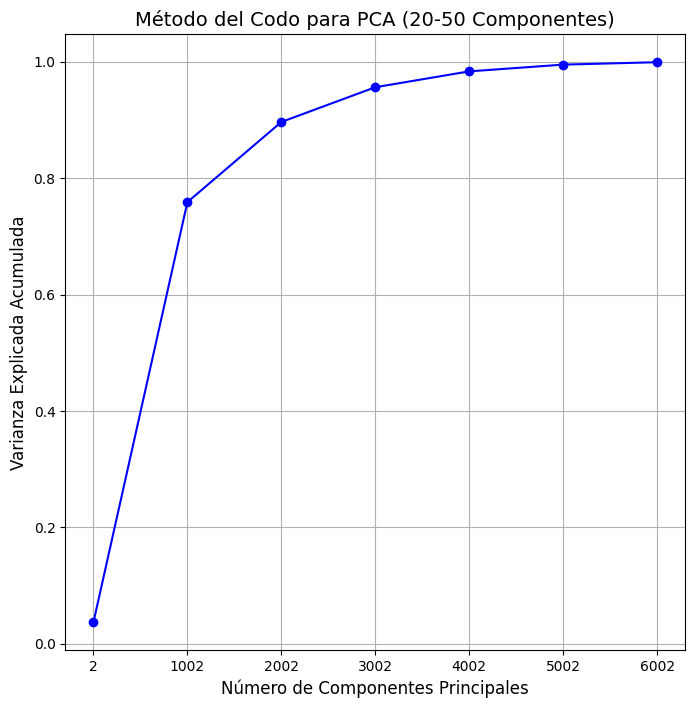

In [10]:
n_components_range = range(2, len(data), 1000)

# # Lista para almacenar la varianza explicada acumulada
# explained_variance_ratio = []

# # Calcular la varianza explicada acumulada para cada número de componentes
# for n in n_components_range:
#     pca = PCA(n_components=n)
#     pca.fit(df_vectorized)  # Ajustar PCA a los datos
#     explained_variance_ratio.append(np.sum(pca.explained_variance_ratio_))  # Varianza explicada acumulada

# with open('../data/output/explained_variance_ratio.pkl', 'wb') as f:
#     pickle.dump(explained_variance_ratio, f)

with open('../data/output/explained_variance_ratio.pkl', 'rb') as f:
    explained_variance_ratio = pickle.load(f)

# Graficar la varianza explicada acumulada respecto al número de componentes
plt.figure(figsize=(8, 8))
plt.plot(n_components_range, explained_variance_ratio, marker='o', linestyle='-', color='b')
plt.xlabel('Número de Componentes Principales', fontsize=12)
plt.ylabel('Varianza Explicada Acumulada', fontsize=12)
plt.title('Método del Codo para PCA (20-50 Componentes)', fontsize=14)
plt.grid(True)
plt.xticks(n_components_range)
plt.show()

In [11]:
dict_explained_variance = dict(zip(list(n_components_range), explained_variance_ratio))
dict_explained_variance

{2: 0.036979038479846835,
 1002: 0.7589831208500996,
 2002: 0.8966952872234497,
 3002: 0.9564152574802118,
 4002: 0.9836951281237873,
 5002: 0.9952958244541756,
 6002: 0.9994127940167322}

In [12]:
explained_variance_ratio_goal = 0.9
n_components = min(dict_explained_variance, key=lambda i: abs(dict_explained_variance[i] - explained_variance_ratio_goal))
n_components = n_components - n_components % 1000
n_components

2000

In [13]:
X_original = X.copy()
df_vectorized_original = df_vectorized.copy()

X = PCA(n_components=n_components).fit_transform(X)
df_vectorized = pd.DataFrame(X)

# Normalize
X = X / np.linalg.norm(X, axis=1, keepdims=True)
df_vectorized = pd.DataFrame(X)

### PCA

In [14]:
# PCA 2D
X_pca_2d = PCA(n_components=2).fit_transform(df_vectorized)
df['pca2d_1'] = X_pca_2d[:, 0]
df['pca2d_2'] = X_pca_2d[:, 1]

# PCA 3D
X_pca_3d = PCA(n_components=3).fit_transform(df_vectorized)
df['pca3d_1'] = X_pca_3d[:, 0]
df['pca3d_2'] = X_pca_3d[:, 1]
df['pca3d_3'] = X_pca_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[knn_idxs[0], 'pca2d_1'], 
               y=df.loc[knn_idxs[0], 'pca2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[knn_idxs[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[knn_idxs[0], 'pca3d_1'], 
                 y=df.loc[knn_idxs[0], 'pca3d_2'], 
                 z=df.loc[knn_idxs[0], 'pca3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[knn_idxs[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
fig.show()

### UMAP

In [15]:
# n_neighbors = 200
# n_neighbors = int(len(df) / k)

n_neighbors = 50 # 6.5x minutos, resultado: vision mas global, no se distinguen tanto los clusters
# n_neighbors = 20 # 2.5x minutos, resultado: no se distinguen los clusters
# n_neighbors = 10 # 1.5x minutos, resultado: puntos muy juntos, se distinguen los clusters
# n_neighbors = 5 # x minutos, resultado: se distinguen bien los clusters, se ven un poco desconectados

min_dist = 0

# UMAP 2D
reducer_2d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, random_state=0)
embedding_2d = reducer_2d.fit_transform(df_vectorized)
df['umap2d_1'] = embedding_2d[:, 0]
df['umap2d_2'] = embedding_2d[:, 1]

# UMAP 3D
reducer_3d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=3, random_state=0)
embedding_3d = reducer_3d.fit_transform(df_vectorized)
df['umap3d_1'] = embedding_3d[:, 0]
df['umap3d_2'] = embedding_3d[:, 1]
df['umap3d_3'] = embedding_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[knn_idxs[0], 'umap2d_1'], 
               y=df.loc[knn_idxs[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[knn_idxs[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[knn_idxs[0], 'umap3d_1'], 
                 y=df.loc[knn_idxs[0], 'umap3d_2'], 
                 z=df.loc[knn_idxs[0], 'umap3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[knn_idxs[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



# Clustering

## Hierarchical

In [43]:
# Create hierarchical clustering with cosine distance

# X_cosine_dist = 1 - cosine_similarity(X)

Z = linkage(X, method='ward')

# Save clustering
joblib.dump(Z, '../data/output/hierarchical_cluster_Z.joblib')

['../data/output/hierarchical_cluster_Z.joblib']

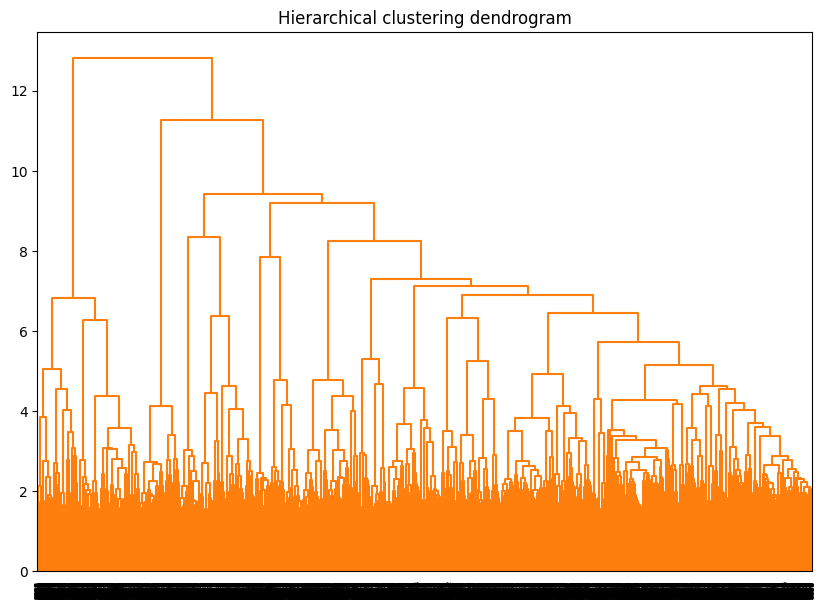

In [44]:
# Load hierarchical clustering
Z = joblib.load('../data/output/hierarchical_cluster_Z.joblib')

# Plot
plt.figure(figsize=(10, 7))
plt.title("Hierarchical clustering dendrogram")
dendrogram(Z, color_threshold=34.824508673362814)
plt.show()

In [45]:
# Definir la función para ajustar la distancia umbral
def ajustar_distancia_umbral(Z, k):
    min_dist = 0
    max_dist = max(Z[:, 2])
    
    while min_dist < max_dist:
        mid_dist = (min_dist + max_dist) / 2
        clusters_HC = fcluster(Z, mid_dist, criterion='distance') - 1
        num_clusters = len(set(clusters_HC))
        
        if num_clusters > k:
            min_dist = mid_dist + 1e-5  # Ajustar el límite inferior
        elif num_clusters < k:
            max_dist = mid_dist - 1e-5  # Ajustar el límite superior
        else:
            return clusters_HC, mid_dist
    
    return clusters_HC, mid_dist

# Rango de clusters deseado
cluster_range = range(3, 51)

# Diccionario para almacenar las distancias umbrales para cada número de clusters
distancias_umbral = {}

# Obtener distancias umbrales para cada número de clusters en el rango
for k_value in cluster_range:
    clusters_HC, distancia_umbral = ajustar_distancia_umbral(Z, k_value)
    distancias_umbral[k_value] = distancia_umbral
    print(f'Número de clusters: {k_value}, Distancia umbral: {distancia_umbral}')

# Mostrar las distancias umbrales para cada número de clusters
print(distancias_umbral)

Número de clusters: 3, Distancia umbral: 9.617499884407387
Número de clusters: 4, Distancia umbral: 9.216770305890412
Número de clusters: 5, Distancia umbral: 8.816040727373437
Número de clusters: 6, Distancia umbral: 8.31512875422722
Número de clusters: 7, Distancia umbral: 8.01458157033949
Número de clusters: 8, Distancia umbral: 7.613851991822514
Número de clusters: 9, Distancia umbral: 7.21312241330554
Número de clusters: 10, Distancia umbral: 7.012757624047053
Número de clusters: 11, Distancia umbral: 6.862484032103188
Número de clusters: 12, Distancia umbral: 6.812392834788566
Número de clusters: 13, Distancia umbral: 6.411663256271591
Número de clusters: 14, Distancia umbral: 6.36157205895697
Número de clusters: 15, Distancia umbral: 6.311480861642348
Número de clusters: 16, Distancia umbral: 6.0109336777546165
Número de clusters: 17, Distancia umbral: 5.6102040992376425
Número de clusters: 18, Distancia umbral: 5.25956571803529
Número de clusters: 19, Distancia umbral: 5.209474

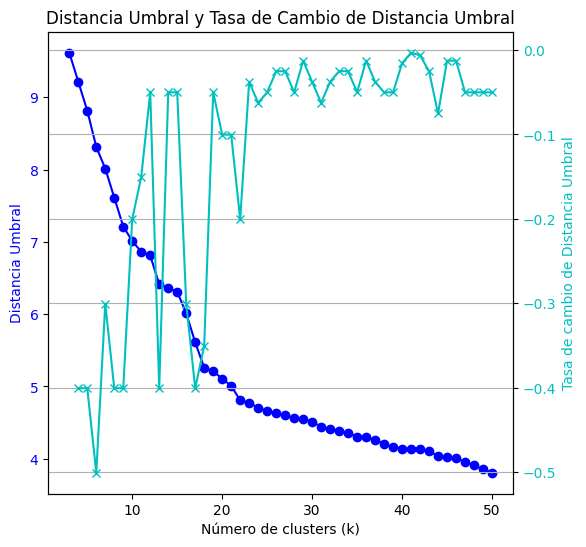

In [46]:
k_range = list(distancias_umbral.keys())
distancias = list(distancias_umbral.values())

# Calcular la tasa de cambio de la distancia umbral
delta_distancia = np.diff(distancias)

# Crear una figura
fig, ax1 = plt.subplots(figsize=(6, 6))

# Graficar la distancia umbral en el eje izquierdo
ax1.plot(k_range, distancias, marker='o', color='b', label='Distancia Umbral')
ax1.set_xlabel('Número de clusters (k)')
ax1.set_ylabel('Distancia Umbral', color='b')
ax1.tick_params(axis='y', labelcolor='b')

# Graficar la tasa de cambio de la distancia umbral en el eje derecho
ax2 = ax1.twinx()
ax2.plot(k_range[1:], delta_distancia, marker='x', color='c', label='Tasa de cambio de Distancia Umbral')
ax2.set_ylabel('Tasa de cambio de Distancia Umbral', color='c')
ax2.tick_params(axis='y', labelcolor='c')

# Título y mostrar el gráfico
plt.title('Distancia Umbral y Tasa de Cambio de Distancia Umbral')
plt.grid(True)
plt.show()

Elegir cantidad de tópicos

In [53]:
k = 18
clusters = list(range(k))
clusters

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

In [54]:
# Asignar el cluster correspondiente
df['cluster_HC'] = fcluster(Z, distancias_umbral[k], criterion='distance') - 1
print(sorted(df['cluster_HC'].unique()))
df["cluster_HC"].value_counts()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


cluster_HC
17    1761
15     795
9      480
12     466
2      410
0      357
14     348
3      335
6      294
8      275
4      193
5      167
13     153
11     133
7      128
16     109
1      107
10     103
Name: count, dtype: int64

## Kmeans

### Metodo del codo

In [22]:
# # Listas para almacenar la inercia y el Silhouette Score de cada k
# inertia = []
# silhouette_scores = []

# # Rango de k para probar
# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Calcular la inercia y el Silhouette Score para cada valor de k
# for k_value in k_range:
#     print(f"Comenzando KMeans para k={k_value}")
#     tic = time.time()

#     kmeans = KMeans(n_clusters=k_value, random_state=0, n_init=100, init='k-means++', max_iter=100)
#     kmeans.fit(X)
    
#     # Almacenar la inercia
#     inertia.append(kmeans.inertia_)
    
#     # Calcular el Silhouette Score y almacenarlo
#     score = silhouette_score(X, kmeans.labels_)
#     silhouette_scores.append(score)
    
                                
#     toc = time.time()
#     print(f"Completado en {toc - tic:.2f} segundos\n")

# # Guardar
# with open('data/output/kmeans_metrics.pkl', 'wb') as f:
#     pickle.dump({'inertia': inertia, 'silhouette_scores': silhouette_scores}, f)

# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Cargar
# with open('data/output/kmeans_metrics.pkl', 'rb') as f:
#     metrics = pickle.load(f)
# inertia = metrics['inertia']
# silhouette_scores = metrics['silhouette_scores']

# # Calcular la tasa de cambio para la inercia y el Silhouette Score
# delta_inertia = np.diff(inertia)
# delta_silhouette = np.diff(silhouette_scores)

# # Crear una figura con dos subgráficos (lado a lado)
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# # Graficar la inercia en el primer subgráfico (izquierda)
# ax1.plot(k_range, inertia, marker='o', color='b', label='Inercia')
# ax1.set_xlabel('Número de clusters (k)')
# ax1.set_ylabel('Inercia', color='b')
# ax1.tick_params(axis='y', labelcolor='b')

# # Graficar la tasa de cambio de la inercia en el eje y derecho
# ax1_twin = ax1.twinx()
# ax1_twin.plot(k_range[1:], delta_inertia, marker='x', color='c', label='Tasa de cambio de Inercia')
# ax1_twin.set_ylabel('Tasa de cambio de Inercia', color='c')
# ax1_twin.tick_params(axis='y', labelcolor='c')

# # Título y leyenda para el primer gráfico
# ax1.set_title('Inercia y Tasa de Cambio de Inercia')
# # ax1.legend(loc='best')

# # Graficar el Silhouette Score en el segundo subgráfico (derecha)
# ax2.plot(k_range, silhouette_scores, marker='o', color='g', label='Silhouette Score')
# ax2.set_xlabel('Número de clusters (k)')
# ax2.set_ylabel('Silhouette Score', color='g')
# ax2.tick_params(axis='y', labelcolor='g')

# # Graficar la tasa de cambio del Silhouette Score en el eje y derecho
# ax2_twin = ax2.twinx()
# ax2_twin.plot(k_range[1:], delta_silhouette, marker='x', color='y', label='Tasa de cambio de Silhouette Score')
# ax2_twin.set_ylabel('Tasa de cambio de Silhouette Score', color='y')
# ax2_twin.tick_params(axis='y', labelcolor='y')

# # Título y leyenda para el segundo gráfico
# ax2.set_title('Silhouette Score y Tasa de Cambio de Silhouette Score')
# # ax2.legend(loc='best')

# # Mostrar el gráfico
# plt.tight_layout()  # Ajusta el espacio entre los subgráficos
# plt.show()

### Clustering final

In [55]:
kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, init='k-means++', max_iter=100).fit(X)
df["cluster_KM"] = kmeans.predict(X)

print(sorted(df['cluster_KM'].unique()))
df["cluster_KM"].value_counts()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


cluster_KM
10    1059
12     699
0      574
3      558
5      462
15     399
1      391
17     310
11     287
6      280
9      252
7      232
16     227
2      227
13     214
14     173
4      147
8      123
Name: count, dtype: int64

Clasificación de un texto

In [24]:
# predicted_cluster = kmeans.predict(topico_vec)
# print(predicted_cluster)

## Results

In [25]:
# Pintar los KNN del topico consultado
# df.loc[indices_knn[0], "cluster_HC"] = -1
# df.loc[indices_knn[0], "cluster_KM"] = -1

Choose clustering type:
* cluster_HC
* cluster_KM

In [78]:
clustering_method = "cluster_KM"

# Agregar la columna 'title' desde el DataFrame 'data'
df['title'] = data['title']

# Convertir la columna clustering_method a tipo categórico (si no lo es)
df[clustering_method] = df[clustering_method].astype('category')

In [97]:
# PCA

# Calcular centroides de cada cluster
centroids = df.groupby(clustering_method)[['pca2d_1', 'pca2d_2']].mean().reset_index()

# Crear gráfico de dispersión interactivo con leyenda discreta
fig = px.scatter(
    df, 
    x='pca2d_1',
    y='pca2d_2',
    size=None,
    color=clustering_method,  # Usar la columna categórica para el color
    title='PCA 2D',
    color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
    hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
    hover_name='title',  # Mostrar el título como identificador principal en el tooltip
    opacity=0.5,
    category_orders={clustering_method: clusters}
)

# Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
fig.update_layout(
    xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
    yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
    width=800,  # Establece un tamaño específico para el ancho
    height=600,  # Establece el mismo tamaño para la altura
    legend_title_text='Cluster'  # Personalizar el título de la leyenda
)

# Personalizar el formato del tooltip
fig.update_traces(
    marker=dict(size=5),
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
                  "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
                  "<b>X:</b> %{x}<br>" +  # Coordenada X
                  "<b>Y:</b> %{y}<br>" +  # Coordenada Y
                  "<extra></extra>"  # Eliminar información adicional no deseada
)

# Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
fig.add_scatter(
    x=df.loc[knn_idxs[0], 'pca2d_1'],
    y=df.loc[knn_idxs[0], 'pca2d_2'],
    mode='markers',
    marker=dict(color='red', size=10, line=dict(color='black', width=2)),
    name='KNNs',
    showlegend=True,
    customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
    hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +
                  "<b>Cluster:</b> %{customdata[0]}<br>" +
                  "<b>X:</b> %{x}<br>" +
                  "<b>Y:</b> %{y}<br>" +
                  "<extra></extra>"
)

# Obtener los colores usados en el gráfico principal
colors = px.colors.qualitative.Alphabet

# Crear un diccionario que mapea cada cluster a un color
cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# Agregar centroides con el color correspondiente de su cluster
for cluster in centroids[clustering_method]:
    centroid = centroids[centroids[clustering_method] == cluster]
    fig.add_scatter(
        x=centroid['pca2d_1'],
        y=centroid['pca2d_2'],
        mode='markers',
        marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
        name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
        showlegend=False
    )

# Mostrar el gráfico
fig.show()

C:\Users\Pablo\AppData\Local\Temp\ipykernel_9196\1701493475.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



In [89]:
# UMAP

# Calcular centroides de cada cluster
centroids = df.groupby(clustering_method)[['umap2d_1', 'umap2d_2']].mean().reset_index()

# Crear gráfico de dispersión interactivo con leyenda discreta
fig = px.scatter(
    df, 
    x='umap2d_1',
    y='umap2d_2',
    size=None,
    color=clustering_method,  # Usar la columna categórica para el color
    title='UMAP 2D',
    color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
    hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
    hover_name='title',  # Mostrar el título como identificador principal en el tooltip
    opacity=0.5,
    category_orders={clustering_method: clusters}
)

# Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
fig.update_layout(
    xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
    yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
    width=800,  # Establece un tamaño específico para el ancho
    height=600,  # Establece el mismo tamaño para la altura
    legend_title_text='Cluster'  # Personalizar el título de la leyenda
)

# Personalizar el formato del tooltip
fig.update_traces(
    marker=dict(size=5),
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
                  "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
                  "<b>X:</b> %{x}<br>" +  # Coordenada X
                  "<b>Y:</b> %{y}<br>" +  # Coordenada Y
                  "<extra></extra>"  # Eliminar información adicional no deseada
)

# Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
fig.add_scatter(
    x=df.loc[knn_idxs[0], 'umap2d_1'],
    y=df.loc[knn_idxs[0], 'umap2d_2'],
    mode='markers',
    marker=dict(color='red', size=10, line=dict(color='black', width=2)),
    name='KNNs',
    showlegend=True,
    customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
    hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +
                  "<b>Cluster:</b> %{customdata[0]}<br>" +
                  "<b>X:</b> %{x}<br>" +
                  "<b>Y:</b> %{y}<br>" +
                  "<extra></extra>"
)

# Obtener los colores usados en el gráfico principal
colors = px.colors.qualitative.Alphabet

# Crear un diccionario que mapea cada cluster a un color
cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# Agregar centroides con el color correspondiente de su cluster
for cluster in centroids[clustering_method]:
    centroid = centroids[centroids[clustering_method] == cluster]
    fig.add_scatter(
        x=centroid['umap2d_1'],
        y=centroid['umap2d_2'],
        mode='markers',
        marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
        name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
        showlegend=False
    )

# Mostrar el gráfico
fig.show()

C:\Users\Pablo\AppData\Local\Temp\ipykernel_9196\559999438.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



# Sumarizacion
Nube de palabras en corpus completo y por clusters

### Corpus

In [98]:
centroid = df_vectorized_original.mean(axis=0)
n_centroid_words = 10
centroid_words = ", ".join([words[idx] for idx in centroid.argsort()[::-1][:n_centroid_words]])
print(f'Full corpus: {centroid_words}')

# word_cloud(centroid_words)

Full corpus: voltage, converter, control, power, current, dc, mmc, fault, multilevel, system


### Clusters

In [100]:
for cluster in clusters:
    cluster_data = df_vectorized_original[(df[clustering_method] == cluster).values]
    centroid = cluster_data.mean(axis=0)
    n_centroid_words = 5
    centroid_words = ", ".join([words[idx] for idx in centroid.argsort()[::-1][:n_centroid_words]])
    print(f'Cluster {cluster}: {centroid_words}')
    # word_cloud(centroid_words)

Cluster 0: voltage, dc, converter, transformer, power
Cluster 1: wind, offshore, farm, power, voltage
Cluster 2: predictive, control, mpc, model, voltage
Cluster 3: voltage, capacitor, sm, mmc, balancing
Cluster 4: fault, detection, diagnosis, open, method
Cluster 5: modulation, voltage, carrier, pwm, pulse
Cluster 6: circulating, current, harmonic, voltage, control
Cluster 7: loss, switching, sic, voltage, converter
Cluster 8: thermal, temperature, loss, junction, power
Cluster 9: impedance, stability, model, system, control
Cluster 10: converter, voltage, power, system, multilevel
Cluster 11: fault, dc, voltage, blocking, converter
Cluster 12: control, voltage, power, current, converter
Cluster 13: motor, drive, voltage, speed, frequency
Cluster 14: photovoltaic, pv, power, solar, system
Cluster 15: fault, protection, dc, current, line
Cluster 16: battery, storage, energy, system, converter
Cluster 17: model, time, simulation, mmc, transient


# Documento representativo
En corpus completo y por clusters

## Centroides

In [31]:
# def encontrar_mas_cercano_al_centroide(df_vectorized, data):
#     centroide = df_vectorized.mean(axis=0)
#     distancias = euclidean_distances(df_vectorized, [centroide])
#     indice_mas_cercano = np.argmin(distancias)
#     texto_mas_cercano = data.iloc[indice_mas_cercano]['abstract']
#     titulo = data.iloc[indice_mas_cercano]['title']
#     return titulo, texto_mas_cercano

### Corpus

In [32]:
# titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(df_vectorized, data)
# display(f"Texto mas representativo del corpus:")
# display(f"Título: {titulo}")
# display(f"Abstract: {texto_mas_cercano}")

### Clusters

In [33]:
# for cluster in clusters:
#     cluster_data_vectorized = df_vectorized.loc[(df[clustering_method] == cluster).values]
#     cluster_data = data[df[clustering_method] == cluster]
#     titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(cluster_data_vectorized, cluster_data)
#     display(f"Cluster {cluster}: Texto mas cercano al centroide")
#     display(f"Título: {titulo}")
#     display(f"Abstract: {texto_mas_cercano}")

## Puntaje Tfidf
Le llamaremos representante al abstract que tenga una mayor cantidad de frecuencia acumulada de palabras del tfid vectorizer, ya que eso implica una mayor participación (profundizar).

Disclaimer: Tenía razón en dudad del método. esto en verdad lo k hace es elegir al que tiene mayor interaccion entre palabras, es decir, el abstract mas complejo.

### Corpus

In [34]:
# abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
# print("Texto más representativo del corpus:")
# print(f"Título: {data['title'].iloc[abstract00]}")
# print(f"Abstract: {data['abstract'].iloc[abstract00]}")

### Clusters

In [35]:
# abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
# display("Texto más representativo del corpus:")
# display(f"Título: {data['title'].iloc[abstract00]}")
# display(f"Abstract: {data['abstract'].iloc[abstract00]}")

In [36]:
# for cluster in clusters:
#     abstract00 = df_vectorized.loc[(df[clustering_method] == cluster).values].sum(axis=1).sort_values(ascending=False).index[0]
#     display(f"Cluster {cluster}: Texto mas representativo")
#     display(f"Título: {data['title'].iloc[abstract00]}")
#     display(f"Abstract: {data['abstract'].iloc[abstract00]}")

Anti representantes (abstracts con baja participación en el tfid vectorizer)

In [37]:
# representantes = [df_vectorized.loc[df[df[clustering_method] == idx].index].sum(axis=1).sort_values().index[0] for idx in clusters]
# for rep in representantes:
#   print('\nTítulo:')
#   display(data.iloc[rep]['title'])
#   print('\nAbstract')
#   display(data.iloc[rep]['Abstract'])

## Similaridad del coseno

### Corpus

In [38]:
# abstract00 = RepresentanteCoseno(df_vectorized)
# titulo = data["title"].iloc[abstract00]
# abstract_mas_representativo = data["abstract"].iloc[abstract00]

# display(f"Texto mas similar a todos los demas en el corpus:")
# display(f"Título: {titulo}")
# display(f"Abstract: {abstract_mas_representativo}")

### Clusters

In [39]:
# for cluster in clusters:
#     abstract00 = RepresentanteCoseno(df_vectorized.loc[(df[clustering_method] == cluster).values])
#     titulo = data["title"].iloc[abstract00]
#     abstract_mas_representativo = data["abstract"].iloc[abstract00]
#     display(f"Cluster {cluster}: Texto mas similar a todos en el cluster")
#     display(f"Título: {titulo}")
#     display(f"Abstract: {abstract_mas_representativo}")

# Grafo de palabras

## Palabras de un abstract especifico

In [40]:
# # Obtener el texto del dataframe
# texto = df.iloc[1000]["abstract"]

# # Procesar el texto con spaCy
# doc = nlp(texto)

# # Crear grafo dirigido con NetworkX
# G = nx.DiGraph()
# for token in doc:
#     if not token.is_stop and not token.is_punct:
#         G.add_node(token.text)
#     for child in token.children:
#         if not child.is_stop and not child.is_punct:
#             G.add_edge(token.text, child.text)

# # Calcular importancia con PageRank
# pagerank = nx.pagerank(G)

# # Crear el grafo con Graphviz
# dot = Digraph(format="png")
# dot.attr(dpi="300", rankdir="LR", bgcolor="white")

# # Agregar nodos con tamaño basado en PageRank
# max_pr = max(pagerank.values()) if pagerank else 1
# for node, pr in pagerank.items():
#     size = str(int(10 + (pr / max_pr) * 30))  # Tamaño proporcional
#     dot.node(node, fontsize=size, shape="ellipse", style="filled", fillcolor="lightblue")

# # Agregar aristas
# for u, v in G.edges():
#     dot.edge(u, v, color="black", penwidth="1.5")

# # Renderizar el grafo en un archivo temporal
# output_file = "Data/Figuras/grafo"
# dot.render(output_file, format="png", cleanup=True)
# # Mostrar la imagen en Jupyter Notebook
# display(Image(filename=output_file + ".png"))

## Entre clusters